# 02 - Policies v2: labels, tuning on dev, evaluation on devtest, analysis (CPU)
Inputs: `data/traces_v2/` (unzipped Kaggle notebook 01 outputs for `dev` and `devtest`), `results/phase1/morph_crf.pkl` (from `scripts/build_morph.py`).
All numbers are written under `results/phase1/`. Tuning uses **dev only**; every reported number is on **devtest**.

Caveats carried into the results: teacher-forcing approximation (PLAN §3); lookahead policies are reported both charged (conservative, used for selection) and uncharged (optimistic); `c` was measured with the 8B target layer-split over 2× T4.

In [1]:
import json, os, pickle
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lgmtp.traces import load_traces, summary, attach_word_labels
from lgmtp.vocab import build_masks
from lgmtp.gpu_traces import read_jsonl, load_tokenizer
from lgmtp.morph import (GoldLexicon, TieredLabeler, build_prefix_model, attach_morph_labels, load_morphtok)
from lgmtp.policies import TokenTable, FixedK
from lgmtp.simulator import load_timing, make_verify, simulate, summarize, legacy_protocol
from lgmtp.tuning import Context, tune_all, evaluate, write_selected, FAMILIES
from lgmtp import analysis

DATA = Path(os.environ.get('LGMTP_DATA', '../data/traces_v2'))
RES = Path(os.environ.get('LGMTP_RES', '../results/phase1')); RES.mkdir(parents=True, exist_ok=True)
MORPH_DIR = Path('../results/phase1')          # CRF model from scripts/build_morph.py
N_BOOT = int(os.environ.get('LGMTP_NBOOT', 1000))
TOKENIZER = 'meta-llama/Llama-3.2-1B-Instruct'   # same tokenizer as the 8B target (asserted on Kaggle)
print('data', DATA.resolve(), '| results', RES.resolve())

data Linguistically-guided-MTP\data\traces_v2 | results Linguistically-guided-MTP\results\phase1


## 1. Load traces (T2 acceptance)

In [2]:
dev, meta_dev = load_traces(DATA / 'traces_dev.npz')
test, meta_test = load_traces(DATA / 'traces_devtest.npz')
timing = load_timing(DATA / 'timing.json')
C_RATIO = timing['c']; VERIFY = make_verify(timing)
out_dev = {r['id']: r for r in read_jsonl(DATA / 'target_outputs_dev.jsonl')}
out_test = {r['id']: r for r in read_jsonl(DATA / 'target_outputs_devtest.jsonl')}
S = {'dev': summary(dev), 'devtest': summary(test)}
for k, m in (('dev', meta_dev), ('devtest', meta_test)):
    S[k]['target_argmax_check'] = m.get('target_argmax_check')
    S[k]['n_hit_max_new'] = sum(len(r['out_ids']) >= m['max_new'] for r in (out_dev if k == 'dev' else out_test).values())
S['timing'] = dict(c=C_RATIO, verify={g: VERIFY(g) for g in range(0, 9)}, t_draft_by_ctx=timing.get('t_draft_by_ctx'))
S['legacy_reference'] = dict(agreement_devtest=0.761, c=0.334)
S['checks'] = dict(agreement_within_2pts=abs(S['devtest']['agreement'] - 0.761) <= 0.02,
                   c_within_10pct=abs(C_RATIO - 0.334) / 0.334 <= 0.10)
(RES / 'traces_summary.json').write_text(json.dumps(S, indent=1))
print(json.dumps(S, indent=1))

{
 "dev": {
  "sentences": 997,
  "positions": 63173,
  "agreement": 0.7611321292324252,
  "mean_H": 0.992243230342865,
  "mean_H_match": 0.6577935814857483,
  "mean_H_mismatch": 2.057938575744629,
  "target_argmax_check": {
   "rate": 0.9990818862488722,
   "positions": 63173,
   "n_diff": 58
  },
  "n_hit_max_new": 1
 },
 "devtest": {
  "sentences": 1012,
  "positions": 66106,
  "agreement": 0.7606873808731431,
  "mean_H": 1.0016372203826904,
  "mean_H_match": 0.6590816378593445,
  "mean_H_mismatch": 2.090496063232422,
  "target_argmax_check": {
   "rate": 0.9990469851450701,
   "positions": 66106,
   "n_diff": 63
  },
  "n_hit_max_new": 0
 },
 "timing": {
  "c": 0.3231310483397806,
  "verify": {
   "0": 1.0,
   "1": 1.0195440004535192,
   "2": 1.0252747785934342,
   "3": 1.033782600022614,
   "4": 1.0428133420879895,
   "5": 1.0598753872853506,
   "6": 1.0628631217231317,
   "7": 1.065660359344337,
   "8": 1.0737610428689595
  },
  "t_draft_by_ctx": {
   "150": 0.022732704999953057,

## 2. Gold labels: words / aksharas (T1) and morphemes (T3 steps 4-6)

In [3]:
tok = load_tokenizer(TOKENIZER)
eos_ids = meta_test['eos_ids']
masks = build_masks(tok, eos_ids)
table = TokenTable.from_tokenizer(tok, masks)
attach_word_labels(dev, tok); attach_word_labels(test, tok)

df_m, _ = load_morphtok('../data/morphtok/hindi.csv')
lex = GoldLexicon.from_dataframe(df_m)
crf = pickle.load(open(MORPH_DIR / 'morph_crf.pkl', 'rb'))
labeler = TieredLabeler(lex, crf)
cov = {'dev': labeler.coverage(r['out_text'] for r in out_dev.values()),
       'devtest': labeler.coverage(r['out_text'] for r in out_test.values())}
(RES / 'morph_coverage.json').write_text(json.dumps(cov, indent=1))
for k, v in cov.items():
    print(k, 'word tokens', v['word_tokens'], {t: round(x['frac'], 3) for t, x in v['tokens'].items()},
          '| word types', v['word_types'], {t: round(x['frac'], 3) for t, x in v['types'].items()})

# causal prefix model: MorphTok + dev target outputs only (never devtest)
prefix_model = build_prefix_model(lex, labeler, [r['out_text'] for r in out_dev.values()], min_count=5)
prefix_model.save(RES / 'prefix_model.pkl.gz')
print('prefix model:', prefix_model.sources, '| global rate', round(prefix_model.global_rate, 4))
attach_morph_labels(dev, labeler); attach_morph_labels(test, labeler)

Linguistically-guided-MTP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dev word tokens 23596 {'gold': 0.665, 'crf': 0.317, 'none': 0.017} | word types 5144 {'gold': 0.346, 'crf': 0.602, 'none': 0.052}
devtest word tokens 24651 {'gold': 0.669, 'crf': 0.314, 'none': 0.016} | word types 5310 {'gold': 0.354, 'crf': 0.594, 'none': 0.053}


prefix model: {'morphtok_words': 60721, 'dev_word_types': 5121, 'dev_word_tokens_by_tier': {'crf': 7484, 'gold': 15700}, 'min_count': 5} | global rate 0.2664


## 3. Legacy-protocol sanity check (T4)
Old protocol on the new devtest traces: random half split, entropy grid, unit verify. Expected (PDF): fixed k=2 ≈ 1.36, entropy ≈ 1.45; a gap > 0.03 must be investigated before going further.

In [4]:
LP = legacy_protocol(test, C_RATIO)
LP['gap'] = dict(fixed=LP['fixed_test']['speedup'] - 1.361, entropy=LP['entropy_test']['speedup'] - 1.452,
                 oracle=LP['oracle_test']['speedup'] - 1.905)
LP['within_0.03'] = all(abs(v) <= 0.03 for k, v in LP['gap'].items() if k != 'oracle')
(RES / 'legacy_protocol.json').write_text(json.dumps(LP, indent=1, default=float))
print(json.dumps(LP, indent=1, default=float))
if not LP['within_0.03']:
    print('WARNING: legacy protocol gap > 0.03 -> investigate before trusting the tables below')

{
 "best_k_dev": 2,
 "fixed_test": {
  "acceptance_rate": 0.6506943489619139,
  "alpha_hat": 0.7505054910201007,
  "tokens_per_verif": 2.2594708562878325,
  "mean_draft_len": 1.9786438141875808,
  "speedup": 1.3782629401111155
 },
 "fixed_k2_all": {
  "acceptance_rate": 0.6512664570303052,
  "alpha_hat": 0.7514752791068581,
  "tokens_per_verif": 2.2591073747522383,
  "mean_draft_len": 1.9779235869045177,
  "speedup": 1.378236876604496
 },
 "entropy_params": {
  "lam": -0.369,
  "beta": 2.0
 },
 "entropy_test": {
  "acceptance_rate": 0.6841917140536149,
  "alpha_hat": 0.7580372250423012,
  "tokens_per_verif": 2.633243500317058,
  "mean_draft_len": 2.4393627140139507,
  "speedup": 1.4725386884977336
 },
 "oracle_test": {
  "acceptance_rate": 1.0,
  "alpha_hat": 1.0,
  "tokens_per_verif": 3.578306764325722,
  "mean_draft_len": 2.630654890133563,
  "speedup": 1.9341714948296993
 },
 "expected": {
  "fixed_k2": 1.361,
  "entropy": 1.452,
  "oracle": 1.905
 },
 "gap": {
  "fixed": 0.01726294

## 4. Tune every policy on dev (T7.2)

In [5]:
ctx = Context(newword_mask=masks.starts_newword, prefix_model=prefix_model, table=table)
selected = tune_all(dev, C_RATIO, VERIFY, ctx, out_dir=RES)
write_selected(selected, RES / 'selected_params.json',
               extra=dict(c=C_RATIO, verify='measured', selection='dev speed-up, lookahead charged',
                          tokenizer=TOKENIZER, eos_ids=eos_ids))
pd.DataFrame([dict(policy=k, **v) for k, v in selected.items()])

FixedK                   8 configs     0.6s  best dev speed-up 1.3563


Entropy                160 configs     9.5s  best dev speed-up 1.4472
NoDraft                  1 configs     0.1s  best dev speed-up 1.0000


WordBoundarySoft        57 configs     7.4s  best dev speed-up 1.1594


WordBoundaryHard         3 configs     0.5s  best dev speed-up 1.1438


AksharaSafeEntropy     528 configs    68.4s  best dev speed-up 1.2354


Hybrid                 704 configs    98.2s  best dev speed-up 1.2474


... (2 outputs left out)

GoldWordOracle           3 configs     0.3s  best dev speed-up 1.3408


Hybrid_ext1            528 configs    66.4s  best dev speed-up 1.2321


MorphEntropy_ext1     2376 configs   351.8s  best dev speed-up 1.4262


,policy,k,lam,beta,tau,min_g,tau_m,max_ext,tau_w,tau_morph,use_akshara
0,FixedK,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Entropy,NaN,-0.683,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NoDraft,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,WordBoundarySoft,NaN,NaN,NaN,0.05,2.0,NaN,NaN,NaN,NaN,NaN
4,WordBoundaryHard,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN
5,AksharaSafeEntropy,NaN,-0.746,4.0,NaN,NaN,0.7,1.0,NaN,NaN,NaN
6,Hybrid,NaN,-0.621,2.0,NaN,NaN,NaN,0.0,0.2,NaN,NaN
7,MorphEntropy,NaN,-0.683,4.0,NaN,NaN,0.5,0.0,NaN,0.10,False
8,MorphOnly,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,0.05,NaN
9,Oracle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Evaluate on devtest (T7.3-7.6)

In [6]:
main, sims = evaluate(test, selected, C_RATIO, VERIFY, ctx, n_boot=N_BOOT)
main.to_csv(RES / 'main_table.csv', index=False)
pd.set_option('display.width', 250)
main.round(4)

,policy,note,params,lookahead,speedup_charged,CI_low,CI_high,speedup_uncharged,speedup_unit_verify,acceptance_rate,...,tokens_per_verif,mean_draft_len,frac_drafts_ending_at_gold_word_boundary,frac_ending_mid_akshara,frac_ending_at_morph_boundary,diff_vs_entropy,diff_CI_low,diff_CI_high,p_better,frac_oracle_gap_closed
0,FixedK,,"{""k"": 2}",0,1.3574,1.3499,1.3657,1.3574,1.3782,0.6513,...,2.2591,1.9779,0.4134,0.5249,0.4268,-0.0944,-0.0993,-0.0897,0.0,0.0000
1,Entropy,,"{""lam"": -0.683, ""beta"": 4.0}",0,1.4518,1.4436,1.4610,1.4518,1.4761,0.7188,...,2.4786,2.1018,0.3050,0.6172,0.3192,0.0000,0.0000,0.0000,0.0,0.1728
2,NoDraft,,{},0,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,...,1.0000,0.0000,NaN,NaN,NaN,-0.4518,-0.4610,-0.4436,0.0,-0.6539
3,WordBoundarySoft,,"{""tau"": 0.05, ""min_g"": 2}",1,1.1607,1.1517,1.1705,1.3413,1.1783,0.5755,...,2.6635,2.9454,0.9274,0.0564,0.9347,-0.2911,-0.2962,-0.2856,0.0,-0.3598
4,WordBoundaryHard,,"{""min_g"": 2}",1,1.1441,1.1350,1.1540,1.3167,1.1617,0.5529,...,2.6830,3.1013,0.9777,0.0164,0.9798,-0.3078,-0.3128,-0.3022,0.0,-0.3903
5,AksharaSafeEntropy,,"{""lam"": -0.746, ""beta"": 4.0, ""tau_m"": 0.7, ""ma...",1,1.2394,1.2309,1.2490,1.4300,1.2581,0.6464,...,2.7587,2.7731,0.5959,0.2863,0.6211,-0.2125,-0.2158,-0.2092,0.0,-0.2159
6,Hybrid,max_ext=0: Entropy + charged lookahead (word c...,"{""lam"": -0.621, ""beta"": 2.0, ""tau_w"": 0.2, ""ma...",1,1.2531,1.2433,1.2641,1.4237,1.2728,0.6327,...,2.8442,2.9791,0.2699,0.6471,0.2841,-0.1987,-0.2025,-0.1949,0.0,-0.1909
7,MorphEntropy,reduces to Entropy (max_ext=0: morph model nev...,"{""lam"": -0.683, ""beta"": 4.0, ""tau_morph"": 0.1,...",0,1.4518,1.4436,1.4610,1.4518,1.4761,0.7188,...,2.4786,2.1018,0.3050,0.6172,0.3192,0.0000,0.0000,0.0000,0.0,0.1728
8,MorphOnly,,"{""tau_morph"": 0.05, ""min_g"": 2}",0,1.3434,1.3347,1.3534,1.3434,1.3657,0.5958,...,2.4861,2.5388,0.4349,0.5008,0.4542,-0.1085,-0.1140,-0.1034,0.0,-0.0257
9,Oracle,,{},0,1.9040,1.8949,1.9138,1.9040,1.9339,1.0000,...,3.5774,2.6301,0.6316,0.3314,0.6421,0.4521,0.4481,0.4564,1.0,1.0000


Rows `Hybrid_ext1` / `MorphEntropy_ext1` are the same families tuned on dev with `max_ext >= 1` (the linguistic condition is actually consulted); the `note` column marks selected configs that reduce to Entropy (user decision 2026-11-02).

## 6. Plots (T7.7)

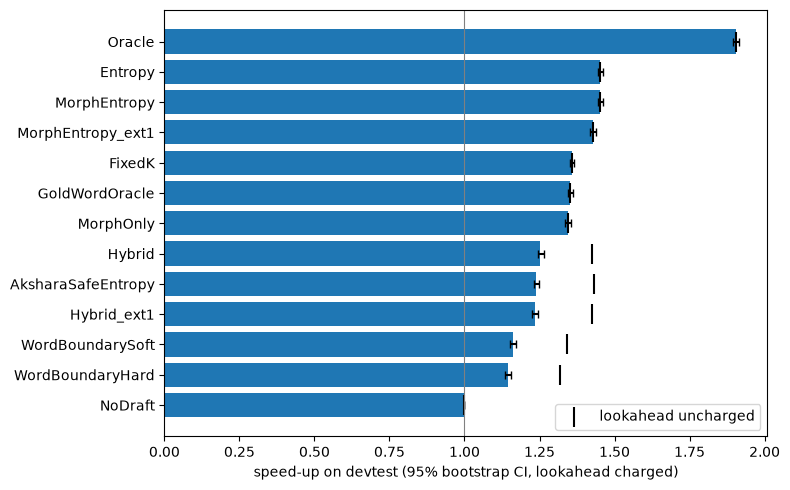

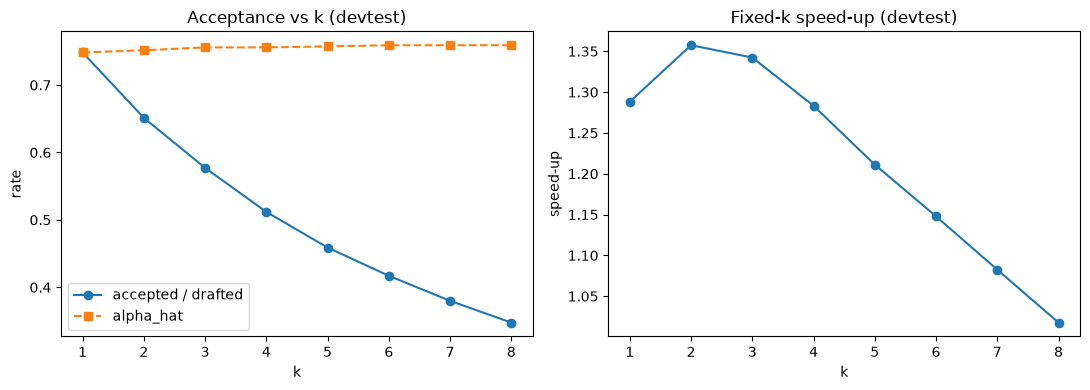

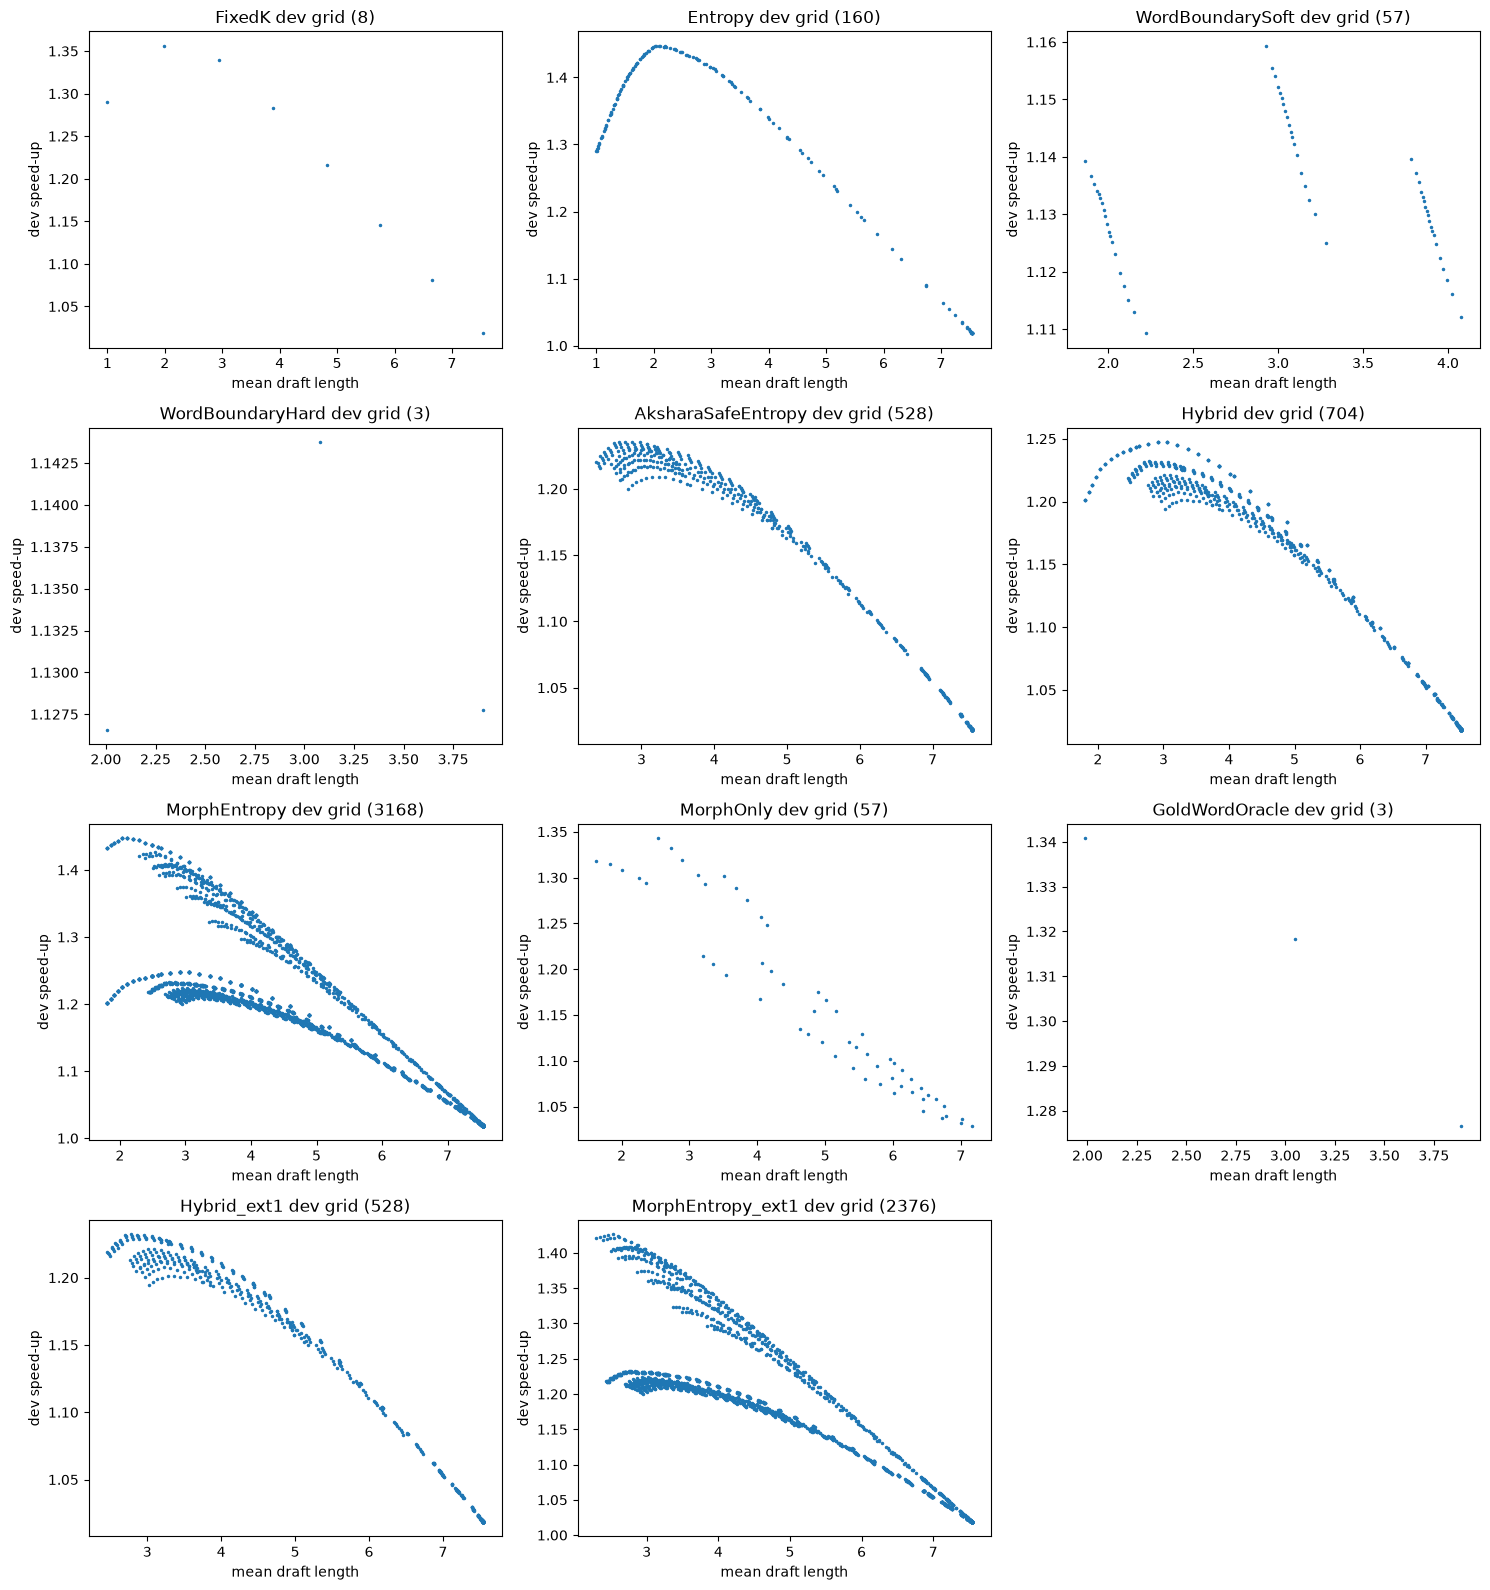

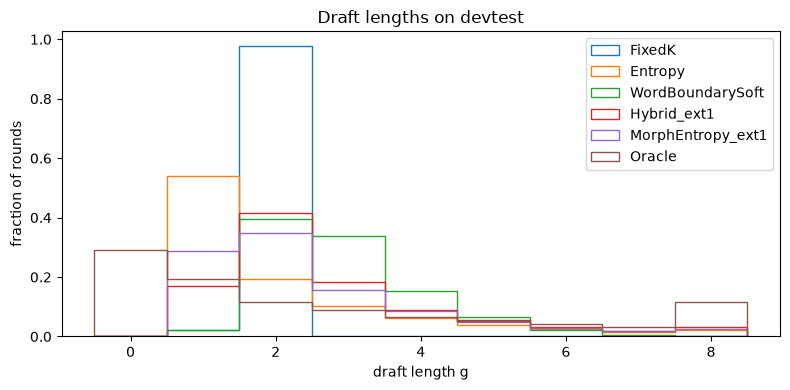

In [7]:
order = main.sort_values('speedup_charged').policy.tolist()
m = main.set_index('policy').loc[order]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order, m.speedup_charged, xerr=[m.speedup_charged - m.CI_low, m.CI_high - m.speedup_charged], capsize=3)
ax.scatter(m.speedup_uncharged, order, marker='|', s=200, color='k', label='lookahead uncharged')
ax.axvline(1, color='gray', lw=0.8); ax.set_xlabel('speed-up on devtest (95% bootstrap CI, lookahead charged)')
ax.legend(); fig.tight_layout(); fig.savefig(RES / 'plot_speedup_ci.png', dpi=160)

ks = range(1, 9)
fk = pd.DataFrame([dict(k=k, **summarize(simulate(test, FixedK(k), k, C_RATIO, VERIFY, record_rounds=False))) for k in ks])
fk.to_csv(RES / 'fixed_k_devtest.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fk.k, fk.acceptance_rate, 'o-', label='accepted / drafted'); ax[0].plot(fk.k, fk.alpha_hat, 's--', label='alpha_hat')
ax[0].set(xlabel='k', ylabel='rate', title='Acceptance vs k (devtest)'); ax[0].legend()
ax[1].plot(fk.k, fk.speedup, 'o-'); ax[1].set(xlabel='k', ylabel='speed-up', title='Fixed-k speed-up (devtest)')
fig.tight_layout(); fig.savefig(RES / 'plot_fixed_k.png', dpi=160)

fams = [f for f in FAMILIES if (RES / f'grid_{f}.csv').exists() and f not in ('NoDraft', 'Oracle')]
fig, axs = plt.subplots(4, 3, figsize=(15, 16)); axs = axs.ravel()
for a, f in zip(axs, fams):
    g = pd.read_csv(RES / f'grid_{f}.csv')
    a.plot(g.mean_draft_len, g.speedup, '.', ms=3); a.set_title(f'{f} dev grid ({len(g)})')
    a.set_xlabel('mean draft length'); a.set_ylabel('dev speed-up')
for a in axs[len(fams):]: a.axis('off')
fig.tight_layout(); fig.savefig(RES / 'plot_dev_sweeps.png', dpi=140)

fig, ax = plt.subplots(figsize=(8, 4))
for f in ['FixedK', 'Entropy', 'WordBoundarySoft', 'Hybrid_ext1', 'MorphEntropy_ext1', 'Oracle']:
    if f in sims:
        ax.hist(sims[f].draft_lens, bins=np.arange(-0.5, 9.5, 1), histtype='step', density=True, label=f)
ax.set(xlabel='draft length g', ylabel='fraction of rounds', title='Draft lengths on devtest'); ax.legend()
fig.tight_layout(); fig.savefig(RES / 'plot_draft_len_hist.png', dpi=160)

## 7. Where do drafts fail? (T8)
Descriptive tables and signed point-biserial correlations with sentence-bootstrap 95% CIs. No automatic interpretation.

=== devtest ===
  pos_bucket  count  mean_H  match_rate  mean_p_target   frac
0          0  26852   1.517       0.659          0.537  0.406
1          1  21965   0.740       0.806          0.735  0.332
2          2  10189   0.519       0.865          0.812  0.154
3          3   4609   0.541       0.863          0.808  0.070
4         4+   2491   0.581       0.845          0.795  0.038
                        pair       r      lo      hi  n_positions  n_sentences
0          H vs word_initial  0.3746  0.3673  0.3822        66106         1012
1         H vs end_cut==WORD -0.2432 -0.2491 -0.2375        66106         1012
2                 H vs match -0.5367 -0.5428 -0.5296        66106         1012
3  H vs morph_boundary_after -0.2661 -0.2720 -0.2604        66106         1012


=== dev ===
  pos_bucket  count  mean_H  match_rate  mean_p_target   frac
0          0  25677   1.499       0.664          0.540  0.406
1          1  20974   0.713       0.808          0.739  0.332
2          2   9727   0.535       0.863          0.808  0.154
3          3   4371   0.537       0.860          0.811  0.069
4         4+   2424   0.691       0.799          0.752  0.038
                        pair       r      lo      hi  n_positions  n_sentences
0          H vs word_initial  0.3709  0.3616  0.3793        63173          997
1         H vs end_cut==WORD -0.2387 -0.2454 -0.2319        63173          997
2                 H vs match -0.5277 -0.5369 -0.5161        63173          997
3  H vs morph_boundary_after -0.2618 -0.2687 -0.2544        63173          997


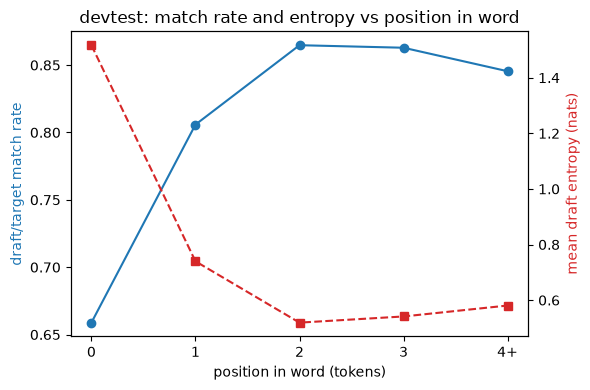

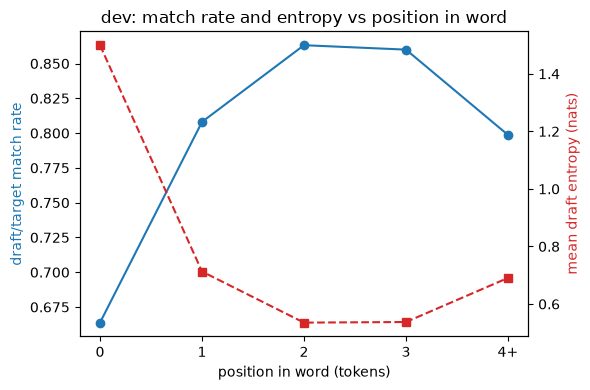

In [8]:
for split, trs in (('devtest', test), ('dev', dev)):
    df = analysis.position_frame(trs, {t.id: t.labels['text'] for t in trs})
    for col in ('pos_bucket', 'start_kind', 'morph_boundary_after', 'token_type'):
        analysis.table_by(df, col).to_csv(RES / f'analysis_{split}_by_{col}.csv', index=False)
    cor = analysis.standard_correlations(df, n_boot=N_BOOT)
    cor.to_csv(RES / f'analysis_{split}_correlations.csv', index=False)
    print(f'=== {split} ==='); print(analysis.table_by(df, 'pos_bucket').round(3).to_string()); print(cor.round(4).to_string())
    analysis.plot_by_position(df, RES / f'analysis_{split}_by_position.png', f'{split}: match rate and entropy vs position in word')

## 8. Does linguistic structure predict failure *beyond* confidence? (added, user decision 2026-11-02)
(a) Match rate of word-initial vs non-initial tokens (and morph-initial vs not) **within entropy deciles**, with the entropy-adjusted difference (count-weighted mean of within-decile differences) and a sentence-bootstrap 95% CI. (b) Logistic regression `match ~ H + top1` vs `+ word_initial + morph_start` (standardised features): coefficients, delta AUC and delta log-likelihood per position, sentence-bootstrap CIs (200 resamples). Linguistic labels are gold labels of the target text (analysis only).

In [9]:
summ = []
for split, trs in (('devtest', test), ('dev', dev)):
    df = analysis.add_morph_start(analysis.position_frame(trs, {t.id: t.labels['text'] for t in trs}))
    for ling in ('word_initial', 'morph_start'):
        tab, s = analysis.conditional_by_entropy(df, ling, n_bins=10, n_boot=N_BOOT)
        tab.to_csv(RES / f'analysis_conditional_{split}_{ling}_by_entropy_decile.csv', index=False)
        summ.append(dict(split=split, **s))
    lg = analysis.logit_beyond_entropy(df, n_boot=200)
    lg.to_csv(RES / f'analysis_conditional_{split}_logit.csv', index=False)
    print(f'=== {split}: logistic regression ==='); print(lg.round(4).to_string())
summ = pd.DataFrame(summ); summ.to_csv(RES / 'analysis_conditional_summary.csv', index=False)
summ.round(4)

=== devtest: logistic regression ===
                                        quantity   value      lo      hi  n_positions  n_sentences  n_boot
0                       coef_std[H] (full model)  0.3001  0.2429  0.3609        66106         1012     200
1                    coef_std[top1] (full model)  1.7227  1.6597  1.7849        66106         1012     200
2            coef_std[word_initial] (full model)  0.1084 -0.0013  0.1993        66106         1012     200
3             coef_std[morph_start] (full model) -0.1198 -0.2036 -0.0098        66106         1012     200
4                              AUC base (H+top1)  0.8718  0.8690  0.8750        66106         1012     200
5     AUC full (H+top1+word_initial+morph_start)  0.8717  0.8687  0.8749        66106         1012     200
6                        delta AUC (full - base) -0.0001 -0.0004  0.0000        66106         1012     200
7  delta mean log-lik per position (full - base)  0.0000  0.0000  0.0002        66106         1012     200


=== dev: logistic regression ===
                                        quantity   value      lo      hi  n_positions  n_sentences  n_boot
0                       coef_std[H] (full model)  0.2996  0.2324  0.3811        63173          997     200
1                    coef_std[top1] (full model)  1.6912  1.6243  1.7730        63173          997     200
2            coef_std[word_initial] (full model)  0.0848 -0.0278  0.1878        63173          997     200
3             coef_std[morph_start] (full model) -0.0836 -0.1797  0.0262        63173          997     200
4                              AUC base (H+top1)  0.8680  0.8642  0.8721        63173          997     200
5     AUC full (H+top1+word_initial+morph_start)  0.8679  0.8641  0.8719        63173          997     200
6                        delta AUC (full - base) -0.0001 -0.0004 -0.0000        63173          997     200
7  delta mean log-lik per position (full - base)  0.0000  0.0000  0.0001        63173          997     200


,split,ling,raw_diff,entropy_adjusted_diff,lo,hi,n_bins,n_boot
0,devtest,word_initial,-0.1715,0.0142,0.0082,0.0202,10,1000
1,devtest,morph_start,-0.1702,0.0133,0.0077,0.0192,10,1000
2,dev,word_initial,-0.1640,0.0173,0.0110,0.0243,10,1000
3,dev,morph_start,-0.1628,0.0171,0.0107,0.0238,10,1000
